# Star catalogue analysis
This activity analyzes properties of over 100,000 stars.

To get started,
- You won't hurt anything by experimenting. If you break it, close the tab and open the activity again to start over.

When you're ready, run the next two code cells. The comments tell you what the code is doing.

In [ ]:
# Import modules that contain functions we need
import pandas as pd                #pandas is a data analysis tool.
import numpy as np                 #We've used numpy before. It contains mathematical functions.
%matplotlib inline
import matplotlib.pyplot as plt    #matplotlib is a tool for graphing data.

# This function draws the H-R diagram's temperature axis: hot on the left,
# a log scale from 25,000 K to 2,000 K, and the spectral classes along the bottom.
def hr_axes():
    plt.xscale("log")
    plt.xlim(25000, 2000)
    plt.ylim(20, -10)
    ticks = [20000, 10000, 7000, 5000, 3000, 2000]
    plt.xticks(ticks, [f"{t:,}" for t in ticks])
    plt.minorticks_off()
    # class boundaries (K), from the Block 2 temperature table
    classes = [(25000, 9600, "O/B"), (9600, 7350, "A"), (7350, 6050, "F"),
               (6050, 5240, "G"), (5240, 3750, "K"), (3750, 2000, "M")]
    ax = plt.gca()
    for hot, cool, name in classes:
        if cool > 2000:
            plt.axvline(cool, color="gray", linewidth=0.5, linestyle=":")
        ax.text((hot * cool) ** 0.5, 0.02, name, transform=ax.get_xaxis_transform(),
                ha="center", fontweight="bold", color="dimgray")


In [ ]:
# Read in data that will be used for the calculations.
data = pd.read_csv("stars.csv")   # stars.csv sits in the same folder as this notebook

## Part One
Let's get acquainted with this data set. Execute the following cells and look at the output to find the answers to the following questions:
- In the table you print out below, what do you think each of the column headings represent?
- How many stars are included in this data set?

When you're ready, scroll down to **Part Two**.

In [ ]:
# We wish to look at the first 5 rows of our data set
data.head(5)

In [ ]:
# The .shape command displays the (number of rows , number of columns) in a file.
data.shape

## Part Two
The code below generates a graph of declination vs. right ascension for each star in the data table.
- The title and axis labels on the graph could use some work. Try editing the code above the graph, then run the code again to see the changes.
- What pattern do you see in the graph? What might explain that pattern?

When you're ready, scroll down to **Part Three**.

In [ ]:
fig = plt.figure(figsize=(15, 4))
plt.scatter(data.ra,data.dec, s=.01)
plt.xlim(24, 0)
plt.title("title?")
plt.xlabel("Label me!")
plt.ylabel("Me, too!");

## Part Three
Now you are going to make some plots of your own to see if you can discern any patterns in the data.

From the data table we printed at the beginning of the notebook we know that the variables you can choose from are *ra*, *dec*, *dist*, *mag*, *absmag*, *ci*, *temp* and *lum*. We'll ignore the other columns as uninteresting to our current task.

Make these **two graphs**. For each one, replace ra and dec in the code below with the two variables, give the graph an appropriate title and axis labels, and run the cell.
1. *ci* (color index) on the x-axis and *temp* on the y-axis.
2. *lum* (luminosity) on the x-axis and *absmag* on the y-axis.

Look at each graph. Do you see any pattern or shape to it? Can you guess why it's like that?

**If you have time**, copy the code cell and make one or both of these: *absmag* against *mag*, and *dist* against *absmag*.

In [ ]:
fig = plt.figure(figsize=(15, 4))
plt.scatter(data.ra,data.dec, s=.01)
plt.title("title?")
plt.xlabel("Label me!")
plt.ylabel("Me, too!");

## Part Four
Execute the code cell below and use the resulting graph to answer the following questions:
- What patterns do you see in the graph?
- The y-axis shows brighter stars at the top and dimmer stars toward the bottom. What's strange about the **absolute magnitude** scale?
- Some stars aren't very hot, but they're very bright because they're so big (called *giants* and *super giants*). Where are those on the graph?
- Other stars are really hot, even though they're small (called *white dwarfs*). How could that happen? Where might you find them on the graph?

The temperature axis runs like a real H-R diagram: hot stars on the left, cool stars on the right. The letters along the bottom are the spectral classes from Block 2.

When you're ready, scroll down to **Part Five**.

In [ ]:
# format the points on the graph
transparency = 0.2
size = 1

# draws a scatter plot
fig = plt.figure(figsize=(10, 6))
plt.scatter(data.temp, data.absmag, s=size, edgecolors='none', alpha=transparency)
hr_axes()   # hot on the left, log scale, spectral classes along the bottom
plt.title("Any idea for a title?")
plt.ylabel("Absolute Magnitude")
plt.xlabel("Temperature (K)");

## Part Five
When you run the second code cell below, the left graph will show what the constellation **Orion** looks like in the sky (its 10 brightest stars). The graph on the right shows those same stars (as red points) on the same absolute magnitude vs. temperature graph from Part Four.
- Using the graphic below, which types of stars are in Orion?
- Look back at your Orion predictions from Block 1. Which star did you mark as the hottest, and which as the biggest? Find them on the graph.
- The first code cell below shows the abbreviation for each constellation. Change `Ori` in the second cell to a constellation you choose and run it again. Is it made of different types of stars?

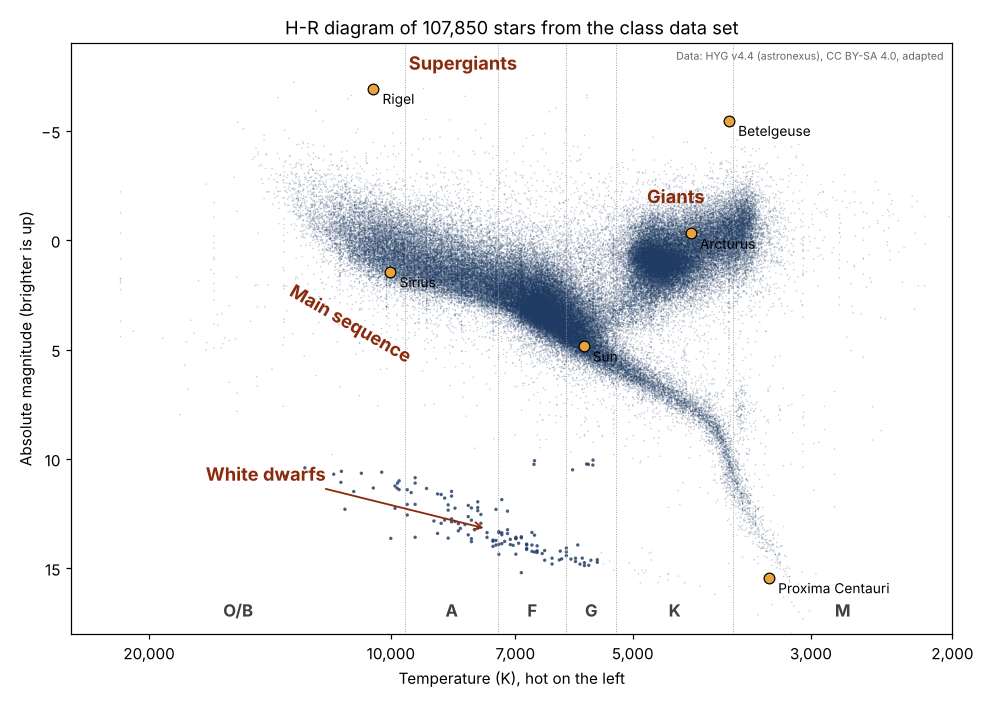


In [ ]:
# These are the abbreviations for all the constellations
data['con'].sort_values().unique()

In [ ]:
# This picks a constellation to plot
constellation = data.query('con == "Ori"') # Ori is short for Orion

plt.close('all')
fig = plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

# This plots where the constellation's 10 brightest stars are in the sky
constellation = constellation.sort_values('mag').head(10)
plt.scatter(constellation['ra'],constellation['dec'])
# write each star's name next to it, where it has one
for _, star in constellation.dropna(subset=['proper']).iterrows():
    plt.annotate(star['proper'], (star['ra'], star['dec']), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.gca().invert_xaxis()
plt.title("A constellation in the sky")
plt.xlabel("right ascension")
plt.ylabel("declination")

plt.subplot(1, 2, 2)
# format the points on the graph
transparency = 0.2
size = 1

# plots the constellation's stars in red over the big graph of all stars
plt.scatter(data['temp'], data['absmag'], s=size, edgecolors='none', alpha=transparency)
plt.scatter(constellation['temp'], constellation['absmag'], color='red', edgecolors='none')
hr_axes()
plt.title("Types of stars in a constellation")
plt.ylabel("Absolute Magnitude")
plt.xlabel("Temperature (K)")
plt.show()

# a table of the same stars, brightest first
constellation[['proper', 'temp', 'absmag', 'mag']]


## Saving Your Work  
- Use the little disk icon in the upper lefthand corner of the screen to make sure that the notebook is saved.
- Go to the folder where the folder is saved and change the file name to something that includes your name.
- Upload the Notebook file to Google Classroom and turn it in.
- Turn in the paper where you wrote your answers the activity questions.

## Credits
This activity has been modified for use in our class by Mr. Buchanan.

Star data: HYG database v4.4 ([astronexus](https://www.astronexus.com/projects/hyg); Hipparcos, Yale Bright Star and Gliese catalogues), [CC BY-SA 4.0](http://creativecommons.org/licenses/by-sa/4.0/). Adapted: columns selected, stars without parallax removed, temp computed from B−V. The labeled H-R diagram in Part Five was made from the same data by Mr. Buchanan.

UCF physics undergraduate Tyler Townsend, who located the data and began the analysis, was funded by Seminole County Schools to make scientific computing a standard part of every middle school science class. The Milky Way scatterplot was added by [Quarknet](https://quarknet.i2u2.org/) Fellow and high school teacher Jeremy Smith, Baltimore, MD. This notebook was designed by [Adam LaMee](https://adamlamee.github.io/), who coordinated its development as the [PhysTEC](https://www.phystec.org/) Teacher-in-residence in the [University of Central Florida's Physics department](https://sciences.ucf.edu/physics/). Thanks to the great folks at [Binder](https://mybinder.org/) and [Google Colaboratory](https://colab.research.google.com/notebooks/intro.ipynb) for making this notebook interactive without you needing to download it or install [Jupyter](https://jupyter.org/) on your own device. Find more activities and license info at [CODINGinK12.org](http://www.codingink12.org).

This adapted notebook is shared under the same [CC BY-SA 4.0](http://creativecommons.org/licenses/by-sa/4.0/) license as the original.
